# 05 · Conclusiones y recomendaciones

**Proyecto:** Análisis de clientes de un servicio de suscripción (Foodie-Fi) · **Etapa 5 de 5**
**Entrada:** métricas guardadas por los notebooks 02, 03 y 04 (`reports/metrics/*.json`)

## Qué hace este notebook
Consolida todo el análisis en un **resumen ejecutivo** y en **6 recomendaciones priorizadas**, cada una con su hallazgo, evidencia, impacto, límites y forma de medirla.
**No recalcula nada desde los datos crudos:** lee las cifras que ya calcularon (y verificaron) los notebooks anteriores, de modo que **no puedan aparecer números distintos en lugares distintos**.
Antes de escribir una sola conclusión, verifica que las cifras de los tres notebooks sean consistentes entre sí.

## Cómo se prioriza
Cada recomendación recibe tres puntajes cualitativos de 1 a 3, asignados por el analista (**no se calculan de los datos**):

| Dimensión | 1 | 2 | 3 |
|---|---|---|---|
| **Impacto** potencial en el negocio | Bajo | Medio | Alto |
| **Esfuerzo** para implementarla | Bajo | Medio | Alto |
| **Solidez de la evidencia** que la respalda | Débil | Media | Fuerte |

**Puntaje de prioridad = Impacto × Solidez ÷ Esfuerzo.** Prioridad **Alta** si es ≥ 4, **Media** si está entre 2 y 4, **Baja** si es < 2.
Ser de prioridad "Media" o "Baja" no significa que sea poco importante: puede ser un frente de gran impacto que requiere más diseño o depende de otra recomendación.

## Glosario
Los datos conservan los nombres originales en inglés; aquí se muestran en español.

| En los datos | En este análisis |
|---|---|
| `trial` | Prueba gratuita (7 días) |
| `basic monthly` | Básico mensual |
| `pro monthly` | Pro mensual |
| `pro annual` | Pro anual |
| `churn` | Cancelación |
| *upgrade* | Mejora de plan (pasar a un plan de mayor nivel) |

## Índice
1. Carga de métricas y control de consistencia
2. Resumen ejecutivo
3. Recomendaciones
4. Priorización
5. Métricas a monitorear
6. Experimentos sugeridos
7. Limitaciones consolidadas
8. Cierre

## 1. Carga de métricas y control de consistencia

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import Markdown, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
MET_DIR = PROJECT_ROOT / "reports" / "metrics"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(PROJECT_ROOT / "src"))
from plot_style import (apply_style, PALETTE, PLAN_COLORS, PLAN_ES, pct, num, miles, PCT_AXIS)
apply_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 140)

def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

m02 = json.loads((MET_DIR / "02_metrics.json").read_text(encoding="utf-8"))
m03 = json.loads((MET_DIR / "03_metrics.json").read_text(encoding="utf-8"))
m04 = json.loads((MET_DIR / "04_metrics.json").read_text(encoding="utf-8"))
print(f"✔ Métricas cargadas: notebook 02 ({len(m02)}), notebook 03 ({len(m03)}), notebook 04 ({len(m04)})")

✔ Métricas cargadas: notebook 02 (34), notebook 03 (21), notebook 04 (12)


In [2]:
# ── Control de consistencia ENTRE notebooks: las mismas magnitudes, calculadas por caminos distintos, deben coincidir ──
checks = {
    "Cancelaciones totales (02) = clientes del bloque 'Perdidos' (04)":
        m02["cancelacion_total"] == m04["grupos"]["Perdidos"]["clientes"],
    "Activos anuales (02) = clientes del bloque 'Activos anuales' (04)":
        m02["anual_activos"] == m04["grupos"]["Activos anuales"]["clientes"],
    "Peso del anual en el valor (02) = peso del bloque anual (04)":
        np.isclose(m02["anual_pct_valor"], m04["grupos"]["Activos anuales"]["pct_valor"]),
    "Retención al día 7 (03) = 1 − cancelaciones en la prueba gratuita (02)":
        np.isclose(m03["retencion_global"]["7"], 1 - m02["cancelacion_en_prueba"] / m02["clientes"]),
    "Tasa mensual mínima observada (04) = mínima de los intervalos (03)":
        np.isclose(m04["tasa_mensual_observada"]["min"], m03["tasa_intervalo_min"]),
    "Anuales vencidos sin evento (03) = 19 (supuesto A1 del notebook 01)":
        m03["anuales_vencidos_sin_evento"] == 19,
    "Clientes activos + cancelados = 1.000 (02)":
        m02["activos_al_corte"] + m02["cancelacion_total"] == m02["clientes"] == 1000,
    "Valor total (04) coincide con la suma de los segmentos":
        np.isclose(m04["valor_total_mensual_estimado"], sum(s["valor"] for s in m04["segmentos"].values())),
}
res = pd.DataFrame({"control": list(checks), "resultado": ["✔ coincide" if bool(v) else "✘ NO coincide" for v in checks.values()]})
display(res)
assert all(bool(v) for v in checks.values()), "Hay cifras inconsistentes entre notebooks: no se escriben conclusiones"
print("✔ Los tres notebooks son consistentes entre sí.")

,control,resultado
0,Cancelaciones totales (02) = clientes del bloque 'Perdidos' (04),✔ coincide
1,Activos anuales (02) = clientes del bloque 'Activos anuales' (04),✔ coincide
2,Peso del anual en el valor (02) = peso del bloque anual (04),✔ coincide
3,Retención al día 7 (03) = 1 − cancelaciones en la prueba gratuita (02),✔ coincide
4,Tasa mensual mínima observada (04) = mínima de los intervalos (03),✔ coincide
5,Anuales vencidos sin evento (03) = 19 (supuesto A1 del notebook 01),✔ coincide
6,Clientes activos + cancelados = 1.000 (02),✔ coincide
7,Valor total (04) coincide con la suma de los segmentos,✔ coincide


✔ Los tres notebooks son consistentes entre sí.


## 2. Resumen ejecutivo

In [3]:
r = m03["retencion_global"]
perd, mens, anu = m04["grupos"]["Perdidos"], m04["grupos"]["Activos mensuales"], m04["grupos"]["Activos anuales"]

display(Markdown(f'''
**En una frase:** el servicio capta bien, pero **pierde clientes de forma constante después de que empiezan a pagar**, y el plan anual, que ya concentra más de un tercio del valor, tiene un **punto ciego de datos** que impide evaluar su retención.

1. **La entrada funciona.** {pct(m02['tasa_conversion'])} de las pruebas gratuitas pasan a un plan de pago, sin diferencias entre meses (p = {num(m02['p_conversion_por_cohorte'])}).
2. **El problema es posterior.** El {pct(m02['pct_cancelacion_tras_pagar'], 0)} de las cancelaciones ocurre después de haber pagado; a los 90 días sigue activo el {pct(r['90'])} de los clientes y a los 120 días el {pct(r['120'])}.
3. **El riesgo es constante y parejo.** La cancelación en planes mensuales ronda el {pct(m04['tasa_mensual_observada']['promedio'])} cada 30 días ({pct(m03['tasa_intervalo_min'])}–{pct(m03['tasa_intervalo_max'])}), sin etapa crítica ni caída con la antigüedad, y **no difiere entre Básico y Pro mensual** (tres métodos) **ni entre cohortes**.
4. **Los clientes crecen mejorando de plan.** Hay {m02['eventos_mejora_de_plan']} mejoras de plan frente a {m02['eventos_cancelacion_desde_mensual']} cancelaciones desde planes mensuales; el {pct(m02['mejora_ventana_completa']['basic monthly'], 0)} de quienes empiezan en Básico mensual mejora de plan en 184 días, y el {pct(m02['pct_mejora_pro_mensual_en_renovacion'], 0)} de los pasajes de Pro mensual a anual ocurre en la fecha de renovación mensual.
5. **El anual pesa y no se puede medir.** Reúne el {pct(anu['clientes'] / m02['activos_al_corte'])} de los clientes activos y el {pct(anu['pct_valor'])} del valor estimado, pero su renovación está **entre {pct(m03['renovacion_anual_rango'][0], 0)} y {pct(m03['renovacion_anual_rango'][1], 0)}** según el supuesto. A precio de lista equivale a un descuento mensual de {pct(m04['descuento_anual'])}: se justifica por el compromiso, no por el precio.
6. **Hay una oportunidad concreta y chica.** {m04['segmentos']['Básico sin cambios']['clientes']} clientes siguen en Básico mensual sin mejorar; cada 10 que pasen a Pro mensual suman {num(m04['uplift_10_basico_a_pro'], 0)} al valor mensual estimado ({pct(m04['uplift_10_pct_valor'])} del total).
'''))


**En una frase:** el servicio capta bien, pero **pierde clientes de forma constante después de que empiezan a pagar**, y el plan anual, que ya concentra más de un tercio del valor, tiene un **punto ciego de datos** que impide evaluar su retención.

1. **La entrada funciona.** 90,8 % de las pruebas gratuitas pasan a un plan de pago, sin diferencias entre meses (p = 0,73).
2. **El problema es posterior.** El 70 % de las cancelaciones ocurre después de haber pagado; a los 90 días sigue activo el 82,0 % de los clientes y a los 120 días el 78,6 %.
3. **El riesgo es constante y parejo.** La cancelación en planes mensuales ronda el 4,2 % cada 30 días (3,6 %–5,4 %), sin etapa crítica ni caída con la antigüedad, y **no difiere entre Básico y Pro mensual** (tres métodos) **ni entre cohortes**.
4. **Los clientes crecen mejorando de plan.** Hay 435 mejoras de plan frente a 209 cancelaciones desde planes mensuales; el 63 % de quienes empiezan en Básico mensual mejora de plan en 184 días, y el 97 % de los pasajes de Pro mensual a anual ocurre en la fecha de renovación mensual.
5. **El anual pesa y no se puede medir.** Reúne el 36,4 % de los clientes activos y el 35,7 % del valor estimado, pero su renovación está **entre 0 % y 76 %** según el supuesto. A precio de lista equivale a un descuento mensual de 16,7 %: se justifica por el compromiso, no por el precio.
6. **Hay una oportunidad concreta y chica.** 125 clientes siguen en Básico mensual sin mejorar; cada 10 que pasen a Pro mensual suman 100 al valor mensual estimado (0,9 % del total).


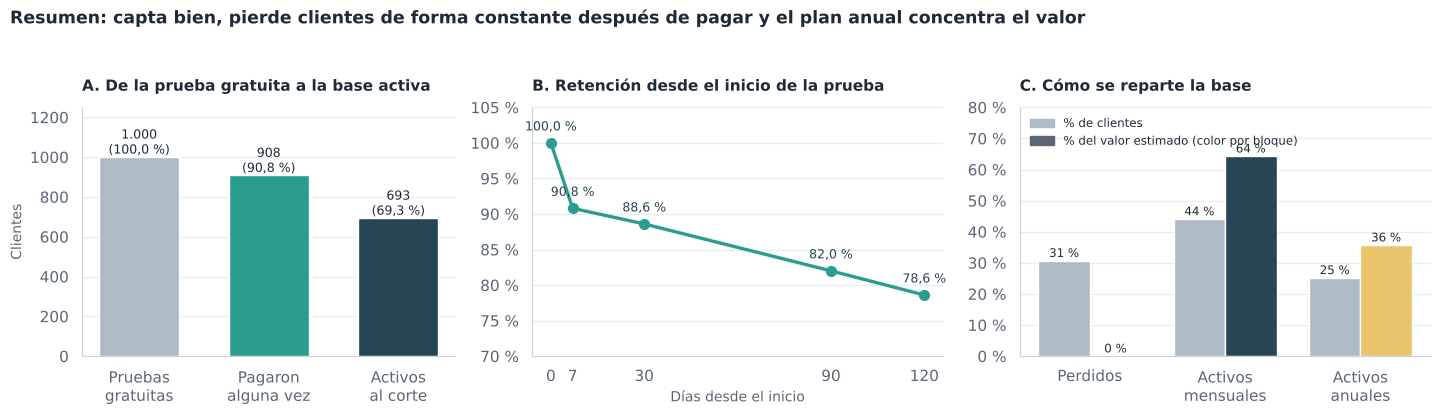

In [4]:
# Gráfico resumen para el README: de las pruebas gratuitas a la base activa
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.2), gridspec_kw={"width_ratios": [1, 1.1, 1.1]})

# A) Embudo
ax = axes[0]
vals = [m02["clientes"], m02["convertidos"], m02["activos_al_corte"]]
labs = ["Pruebas\ngratuitas", "Pagaron\nalguna vez", "Activos\nal corte"]
cols = [PALETTE["slate"], PALETTE["teal"], PALETTE["navy"]]
ax.bar(labs, vals, color=cols, width=.62)
for i, v in enumerate(vals):
    ax.text(i, v + 18, f"{miles(v)}\n({pct(v / vals[0])})", ha="center", fontsize=9)
ax.set_ylim(0, 1250); ax.set_title("A. De la prueba gratuita a la base activa", fontsize=11)
ax.set_ylabel("Clientes")

# B) Retención
ax = axes[1]
dias = [0, 7, 30, 90, 120]
ret = [1.0] + [m03["retencion_global"][str(d)] for d in dias[1:]]
ax.plot(dias, ret, "-o", color=PALETTE["teal"], lw=2.4, ms=7)
for d, v in zip(dias, ret):
    ax.annotate(pct(v), (d, v), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9, color=PALETTE["navy"])
ax.set_ylim(0.7, 1.05); ax.yaxis.set_major_formatter(PCT_AXIS); ax.set_xticks(dias)
ax.set_title("B. Retención desde el inicio de la prueba", fontsize=11); ax.set_xlabel("Días desde el inicio")

# C) Bloques: clientes vs valor
ax = axes[2]
bloques = ["Perdidos", "Activos mensuales", "Activos anuales"]
pc = [m04["grupos"][b]["clientes"] / 1000 for b in bloques]
pv = [m04["grupos"][b]["pct_valor"] for b in bloques]
x = np.arange(3); w = .38
ax.bar(x - w / 2, pc, w, color=PALETTE["slate"], label="% de clientes")
ax.bar(x + w / 2, pv, w, color=[PALETTE["coral"], PLAN_COLORS["pro monthly"], PLAN_COLORS["pro annual"]], label="% del valor estimado")
for i in range(3):
    ax.text(i - w / 2, pc[i] + .012, f"{pc[i] * 100:.0f} %", ha="center", fontsize=8.5)
    ax.text(i + w / 2, pv[i] + .012, f"{pv[i] * 100:.0f} %", ha="center", fontsize=8.5)
ax.set_xticks(x); ax.set_xticklabels(["Perdidos", "Activos\nmensuales", "Activos\nanuales"])
ax.yaxis.set_major_formatter(PCT_AXIS); ax.set_ylim(0, .8)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=PALETTE["slate"]), plt.Rectangle((0, 0), 1, 1, color=PALETTE["muted"])],
          ["% de clientes", "% del valor estimado (color por bloque)"], frameon=False, fontsize=8.5, loc="upper left")
ax.set_title("C. Cómo se reparte la base", fontsize=11)

fig.suptitle("Resumen: capta bien, pierde clientes de forma constante después de pagar y el plan anual concentra el valor", x=0.01, ha="left",
             fontsize=12.5, fontweight="bold", color=PALETTE["ink"])
fig.tight_layout(rect=(0, 0, 1, 0.93)); save(fig, "05_executive_summary.png")

## 3. Recomendaciones
Seis recomendaciones en formato **Hallazgo / Evidencia / Impacto / Recomendación**, con sus **límites** y **cómo medirlas**. Cada una cita el notebook de origen.
Las cifras vienen de las métricas guardadas; los puntajes de priorización se asignan en la sección 4.

In [5]:
seg = m04["segmentos"]
tasa_m = m04["tasa_mensual_observada"]
perdidas_6m = lambda h: 100 * (1 - (1 - h) ** 6)                       # cancelaciones esperables por cada 100 clientes mensuales en 6 meses (tasa constante)
evitadas = perdidas_6m(tasa_m["promedio"]) - perdidas_6m(tasa_m["promedio"] - 0.01)

def n_por_grupo(p1, p2, alpha=0.05, power=0.80):
    # tamaño de muestra por grupo para comparar dos proporciones (aproximación normal, prueba bilateral)
    z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    pb = (p1 + p2) / 2
    return int(np.ceil(((z_a * np.sqrt(2 * pb * (1 - pb)) + z_b * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2) / (p1 - p2) ** 2))

assert 195 <= n_por_grupo(0.10, 0.20) <= 205                           # control contra el valor de referencia (~199 por grupo)
n_basico = seg["Básico sin cambios"]["clientes"]
n_necesario = n_por_grupo(0.10, 0.20)
n_pro = seg["Pro mensual directo"]["clientes"] + seg["Mejoraron a Pro mensual"]["clientes"]

assert evitadas > 3                                                    # bajar 1 punto la tasa mensual evita varias cancelaciones por cada 100 clientes
assert n_basico // 2 < n_necesario                                     # el segmento solo no alcanza para un experimento con grupo de control
assert m04["ventaja_anual_12m"]["min"] > 0 and m04["tasa_equilibrio_anual"] < tasa_m["min"]
print("✔ Cifras de apoyo verificadas.")

✔ Cifras de apoyo verificadas.


In [6]:
display(Markdown(f'''
### R1 · Registrar como eventos las renovaciones y cancelaciones del plan anual
- **Hallazgo:** hoy no se puede medir cuántos clientes anuales renuevan.
- **Evidencia:** de {m03['anuales_vencidos']} planes anuales vencidos al corte, {m03['anuales_vencidos_cancelaron']} cancelaron al día 365 y {m03['anuales_vencidos_sin_evento']} no registran ningún evento: la renovación está entre {pct(m03['renovacion_anual_rango'][0], 0)} y {pct(m03['renovacion_anual_rango'][1], 0)}. El plan anual reúne el {pct(m02['anual_pct_base_activa'])} de la base activa y el {pct(m02['anual_pct_valor'])} del valor estimado *(notebooks 02 y 03)*.
- **Impacto:** desbloquea las decisiones sobre el segmento que concentra más de un tercio del valor. Las conclusiones sobre planes mensuales no dependen de esto (la cancelación acumulada global sólo cambia de {pct(m02['cancelacion_total'] / m02['clientes'])} a {pct(m03['cancelacion_total_peor_caso'])} en el peor caso).
- **Recomendación:** registrar la renovación y la cancelación de cada plan anual como eventos con fecha, tal como ya se hace con las demás transiciones.
- **Cómo medirlo:** tasa de renovación anual por cohorte de compra. **Límite:** requiere esperar 12 meses para obtener las primeras lecturas completas.

### R2 · Sostener acciones de retención durante los primeros 6 meses de un plan mensual, iguales para Básico y Pro
- **Hallazgo:** la pérdida de clientes ocurre sobre todo después de pagar y a un ritmo constante, sin etapa crítica ni diferencias entre planes o cohortes.
- **Evidencia:** el {pct(m02['pct_cancelacion_tras_pagar'], 0)} de las cancelaciones ocurre tras pagar; la retención a 90 días es {pct(m03['retencion_global']['90'])}; la cancelación va de {pct(m03['tasa_intervalo_min'])} a {pct(m03['tasa_intervalo_max'])} cada 30 días sin tendencia (p = {num(m03['p_tendencia_tasa'])}); no hay diferencias entre Básico y Pro mensual (razón de tasas {num(m02['razon_tasas_basico_vs_pro'])}, p = {num(m02['p_cancelacion_basico_vs_pro'])}; log-rank p = {num(m03['p_logrank_basico_vs_pro'])}) ni entre cohortes (p = {num(m03['p_cohortes_90d'])}) *(notebooks 02 y 03)*.
- **Impacto:** como ilustración aritmética, bajar un punto porcentual la tasa mensual (de {pct(tasa_m['promedio'])} a {pct(tasa_m['promedio'] - 0.01)}) evitaría unas {num(evitadas, 0)} cancelaciones por cada 100 clientes mensuales en 6 meses (supone tasa constante; no es una proyección).
- **Recomendación:** diseñar acciones de retención **continuas** (contacto periódico, beneficios de permanencia) para todos los clientes mensuales, sin segmentarlas por plan ni por mes de alta, y probar su efecto con grupo de control.
- **Cómo medirlo:** tasa de cancelación por 30 días y retención a 90 días, siempre en ventanas equivalentes. **Límite:** los datos no explican por qué cancelan (ver R5) ni permiten extrapolar más allá de 6 meses (A2).

### R3 · Probar una propuesta de mejora de plan para los clientes que se quedaron en Básico mensual
- **Hallazgo:** los clientes mejoran de plan con frecuencia, pero hay un grupo que no lo hace.
- **Evidencia:** el {pct(m02['mejora_ventana_completa']['basic monthly'], 0)} de quienes empiezan en Básico mensual mejora de plan en 184 días; {n_basico} siguen sin cambios y {m04['basico_sin_cambios_184d']} de ellos llevan 184 días o más en ese plan *(notebooks 02 y 04)*.
- **Impacto:** cada 10 clientes que pasen a Pro mensual suman {num(m04['uplift_10_basico_a_pro'], 0)} al valor mensual estimado ({pct(m04['uplift_10_pct_valor'])} del total); es aritmética con precios de lista, no una proyección.
- **Recomendación:** lanzar una propuesta de mejora dirigida a este segmento **con un grupo de control**. Con sólo {n_basico} clientes (≈ {n_basico // 2} por grupo) un experimento detectaría únicamente efectos muy grandes (para pasar de 10 % a 20 % harían falta unos {n_necesario} por grupo), por lo que conviene **acumular clientes nuevos del plan básico** durante varios meses.
- **Cómo medirlo:** % que mejora de plan en 60 días, grupo tratado frente a control. **Límite:** no se sabe por qué no mejoraron.

### R4 · Evaluar la oferta del plan anual en la renovación mensual de los clientes Pro mensual
- **Hallazgo:** el pasaje al anual ocurre casi siempre en la renovación mensual, y es una apuesta por el compromiso, no por el precio.
- **Evidencia:** el {pct(m02['pct_mejora_pro_mensual_en_renovacion'], 0)} de las mejoras de Pro mensual a anual ocurre en la fecha de renovación; el anual equivale a un descuento mensual de {pct(m04['descuento_anual'])}; con la cancelación mensual observada ({pct(tasa_m['min'])}–{pct(tasa_m['max'])}) rinde entre {pct(m04['ventaja_anual_12m']['min'])} y {pct(m04['ventaja_anual_12m']['max'])} más a 12 meses (promedio {pct(m04['ventaja_anual_12m']['promedio'])}), y el equilibrio está en {pct(m04['tasa_equilibrio_anual'])} *(notebooks 02 y 04)*.
- **Impacto:** la ventaja existe pero es delgada si la cancelación mensual es baja, y no incluye la renovación al año (desconocida, ver R1).
- **Recomendación:** probar la oferta **con grupo de control** sobre los {n_pro} clientes Pro mensual, midiendo cancelación y renovación, no sólo conversión. **Condicionar la decisión a contar con R1.**
- **Cómo medirlo:** % que pasa al anual, cancelación a 12 meses y renovación. **Límite:** análisis de equilibrio ilustrativo (tasa constante, precios de lista).

### R5 · Registrar el motivo de cancelación y atributos básicos del cliente
- **Hallazgo:** los datos describen qué hacen los clientes, pero no por qué ni quiénes son.
- **Evidencia:** hay {m02['cancelacion_total']} cancelaciones sin motivo registrado; la segmentación sólo puede ser conductual (no hay país, canal ni uso); no se puede explicar por qué {n_basico} clientes no mejoran de plan *(notebooks 02 y 04)*.
- **Impacto:** habilita retención dirigida y segmentación real; hoy toda acción debe aplicarse de forma uniforme.
- **Recomendación:** capturar el motivo de cancelación (campo breve al cancelar) y atributos como canal de origen, país y uso del servicio.
- **Cómo medirlo:** % de cancelaciones con motivo registrado. **Límite:** el motivo declarado puede diferir del motivo real.

### R6 · Instalar un tablero de seguimiento mensual con ventanas equivalentes y pruebas estadísticas
- **Hallazgo:** con cohortes pequeñas es fácil confundir ruido con señal y comparar plazos distintos.
- **Evidencia:** la cohorte con mejor retención a 90 días ({pct(m03['retencion_90d_max']['valor'])}, {m03['retencion_90d_max']['cohorte']}) y la peor ({pct(m03['retencion_90d_min']['valor'])}, {m03['retencion_90d_min']['cohorte']}) parecen muy distintas, pero no lo son (p = {num(m03['p_cohortes_90d'])}); filtrar clientes por "seguimiento mínimo" sobrestimaría la retención *(notebook 03)*.
- **Impacto:** evita decisiones basadas en diferencias que el azar explica y permite ver si las acciones de R2 a R4 funcionan.
- **Recomendación:** publicar cada mes los indicadores de la sección 5, siempre en **ventanas equivalentes**, con intervalos de confianza y la segmentación de 7 grupos del notebook 04.
- **Cómo medirlo:** que cada indicador se actualice mensualmente con su intervalo. **Límite:** requiere disciplina para no sobreinterpretar cohortes chicas.
'''))


### R1 · Registrar como eventos las renovaciones y cancelaciones del plan anual
- **Hallazgo:** hoy no se puede medir cuántos clientes anuales renuevan.
- **Evidencia:** de 25 planes anuales vencidos al corte, 6 cancelaron al día 365 y 19 no registran ningún evento: la renovación está entre 0 % y 76 %. El plan anual reúne el 36,4 % de la base activa y el 35,7 % del valor estimado *(notebooks 02 y 03)*.
- **Impacto:** desbloquea las decisiones sobre el segmento que concentra más de un tercio del valor. Las conclusiones sobre planes mensuales no dependen de esto (la cancelación acumulada global sólo cambia de 30,7 % a 32,6 % en el peor caso).
- **Recomendación:** registrar la renovación y la cancelación de cada plan anual como eventos con fecha, tal como ya se hace con las demás transiciones.
- **Cómo medirlo:** tasa de renovación anual por cohorte de compra. **Límite:** requiere esperar 12 meses para obtener las primeras lecturas completas.

### R2 · Sostener acciones de retención durante los primeros 6 meses de un plan mensual, iguales para Básico y Pro
- **Hallazgo:** la pérdida de clientes ocurre sobre todo después de pagar y a un ritmo constante, sin etapa crítica ni diferencias entre planes o cohortes.
- **Evidencia:** el 70 % de las cancelaciones ocurre tras pagar; la retención a 90 días es 82,0 %; la cancelación va de 3,6 % a 5,4 % cada 30 días sin tendencia (p = 0,19); no hay diferencias entre Básico y Pro mensual (razón de tasas 1,05, p = 0,78; log-rank p = 0,32) ni entre cohortes (p = 0,19) *(notebooks 02 y 03)*.
- **Impacto:** como ilustración aritmética, bajar un punto porcentual la tasa mensual (de 4,2 % a 3,2 %) evitaría unas 5 cancelaciones por cada 100 clientes mensuales en 6 meses (supone tasa constante; no es una proyección).
- **Recomendación:** diseñar acciones de retención **continuas** (contacto periódico, beneficios de permanencia) para todos los clientes mensuales, sin segmentarlas por plan ni por mes de alta, y probar su efecto con grupo de control.
- **Cómo medirlo:** tasa de cancelación por 30 días y retención a 90 días, siempre en ventanas equivalentes. **Límite:** los datos no explican por qué cancelan (ver R5) ni permiten extrapolar más allá de 6 meses (A2).

### R3 · Probar una propuesta de mejora de plan para los clientes que se quedaron en Básico mensual
- **Hallazgo:** los clientes mejoran de plan con frecuencia, pero hay un grupo que no lo hace.
- **Evidencia:** el 63 % de quienes empiezan en Básico mensual mejora de plan en 184 días; 125 siguen sin cambios y 95 de ellos llevan 184 días o más en ese plan *(notebooks 02 y 04)*.
- **Impacto:** cada 10 clientes que pasen a Pro mensual suman 100 al valor mensual estimado (0,9 % del total); es aritmética con precios de lista, no una proyección.
- **Recomendación:** lanzar una propuesta de mejora dirigida a este segmento **con un grupo de control**. Con sólo 125 clientes (≈ 62 por grupo) un experimento detectaría únicamente efectos muy grandes (para pasar de 10 % a 20 % harían falta unos 199 por grupo), por lo que conviene **acumular clientes nuevos del plan básico** durante varios meses.
- **Cómo medirlo:** % que mejora de plan en 60 días, grupo tratado frente a control. **Límite:** no se sabe por qué no mejoraron.

### R4 · Evaluar la oferta del plan anual en la renovación mensual de los clientes Pro mensual
- **Hallazgo:** el pasaje al anual ocurre casi siempre en la renovación mensual, y es una apuesta por el compromiso, no por el precio.
- **Evidencia:** el 97 % de las mejoras de Pro mensual a anual ocurre en la fecha de renovación; el anual equivale a un descuento mensual de 16,7 %; con la cancelación mensual observada (3,6 %–5,4 %) rinde entre 0,9 % y 11,0 % más a 12 meses (promedio 4,3 %), y el equilibrio está en 3,4 % *(notebooks 02 y 04)*.
- **Impacto:** la ventaja existe pero es delgada si la cancelación mensual es baja, y no incluye la renovación al año (desconocida, ver R1).
- **Recomendación:** probar la oferta **con grupo de control** sobre los 316 clientes Pro mensual, midiendo cancelación y renovación, no sólo conversión. **Condicionar la decisión a contar con R1.**
- **Cómo medirlo:** % que pasa al anual, cancelación a 12 meses y renovación. **Límite:** análisis de equilibrio ilustrativo (tasa constante, precios de lista).

### R5 · Registrar el motivo de cancelación y atributos básicos del cliente
- **Hallazgo:** los datos describen qué hacen los clientes, pero no por qué ni quiénes son.
- **Evidencia:** hay 307 cancelaciones sin motivo registrado; la segmentación sólo puede ser conductual (no hay país, canal ni uso); no se puede explicar por qué 125 clientes no mejoran de plan *(notebooks 02 y 04)*.
- **Impacto:** habilita retención dirigida y segmentación real; hoy toda acción debe aplicarse de forma uniforme.
- **Recomendación:** capturar el motivo de cancelación (campo breve al cancelar) y atributos como canal de origen, país y uso del servicio.
- **Cómo medirlo:** % de cancelaciones con motivo registrado. **Límite:** el motivo declarado puede diferir del motivo real.

### R6 · Instalar un tablero de seguimiento mensual con ventanas equivalentes y pruebas estadísticas
- **Hallazgo:** con cohortes pequeñas es fácil confundir ruido con señal y comparar plazos distintos.
- **Evidencia:** la cohorte con mejor retención a 90 días (93,2 %, 2020-08) y la peor (73,4 %, 2020-10) parecen muy distintas, pero no lo son (p = 0,19); filtrar clientes por "seguimiento mínimo" sobrestimaría la retención *(notebook 03)*.
- **Impacto:** evita decisiones basadas en diferencias que el azar explica y permite ver si las acciones de R2 a R4 funcionan.
- **Recomendación:** publicar cada mes los indicadores de la sección 5, siempre en **ventanas equivalentes**, con intervalos de confianza y la segmentación de 7 grupos del notebook 04.
- **Cómo medirlo:** que cada indicador se actualice mensualmente con su intervalo. **Límite:** requiere disciplina para no sobreinterpretar cohortes chicas.


## 4. Priorización
Puntajes cualitativos asignados por el analista (ver criterios al inicio); el puntaje de prioridad se calcula con la fórmula **Impacto × Solidez ÷ Esfuerzo**.

,id,recomendación,tipo,impacto,esfuerzo,solidez,comentario,puntaje,prioridad
0,R6,Tablero mensual con ventanas equivalentes,Seguimiento,2,1,3,Barato y metodológicamente sólido; hace medibles las demás,"6,0",Alta
1,R1,Registrar renovaciones y cancelaciones del plan anual,Datos,3,2,3,Brecha de datos demostrada; desbloquea decisiones sobre 1/3 del valor,"4,5",Alta
2,R5,Registrar motivo de cancelación y atributos del cliente,Datos,3,2,3,Brecha de datos demostrada; habilita retención dirigida,"4,5",Alta
3,R3,Propuesta de mejora para Básico sin cambios,Acción comercial,2,1,2,"Oportunidad concreta, pero chica y sin explicación del comportamiento","4,0",Alta
4,R2,Retención continua en los primeros 6 meses,Acción comercial,3,2,2,"Principal frente de pérdida, pero se desconoce el porqué","3,0",Media
5,R4,Oferta del anual en la renovación mensual,Acción comercial,3,2,1,Depende de R1: la renovación al año es desconocida,"1,5",Baja


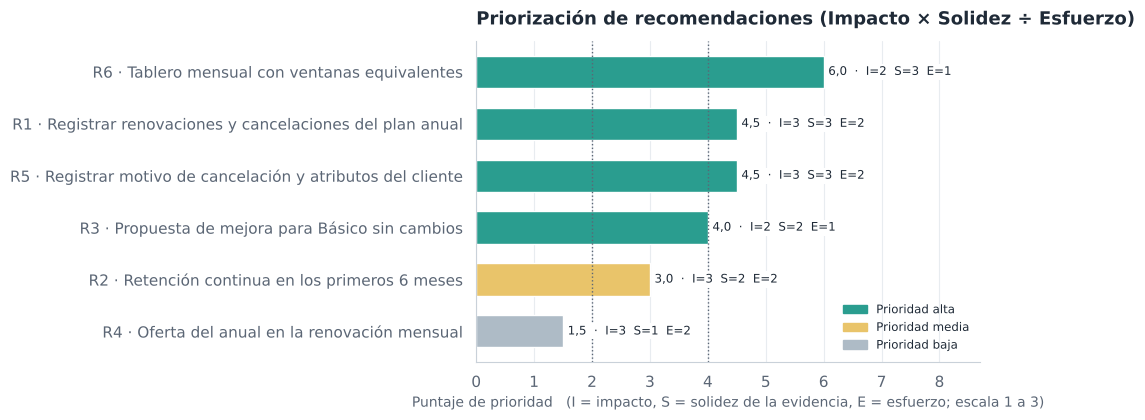

In [7]:
reco = pd.DataFrame([
    ("R1", "Registrar renovaciones y cancelaciones del plan anual",   "Datos",             3, 2, 3, "Brecha de datos demostrada; desbloquea decisiones sobre 1/3 del valor"),
    ("R2", "Retención continua en los primeros 6 meses",              "Acción comercial",  3, 2, 2, "Principal frente de pérdida, pero se desconoce el porqué"),
    ("R3", "Propuesta de mejora para Básico sin cambios",             "Acción comercial",  2, 1, 2, "Oportunidad concreta, pero chica y sin explicación del comportamiento"),
    ("R4", "Oferta del anual en la renovación mensual",               "Acción comercial",  3, 2, 1, "Depende de R1: la renovación al año es desconocida"),
    ("R5", "Registrar motivo de cancelación y atributos del cliente", "Datos",             3, 2, 3, "Brecha de datos demostrada; habilita retención dirigida"),
    ("R6", "Tablero mensual con ventanas equivalentes",               "Seguimiento",       2, 1, 3, "Barato y metodológicamente sólido; hace medibles las demás"),
], columns=["id", "recomendación", "tipo", "impacto", "esfuerzo", "solidez", "comentario"])
reco["puntaje"] = reco["impacto"] * reco["solidez"] / reco["esfuerzo"]
reco["prioridad"] = np.select([reco["puntaje"] >= 4, reco["puntaje"] >= 2], ["Alta", "Media"], default="Baja")
reco = reco.sort_values("puntaje", ascending=False).reset_index(drop=True)

assert reco[["impacto", "esfuerzo", "solidez"]].isin([1, 2, 3]).all().all() and len(reco) == 6
display(reco.assign(puntaje=reco["puntaje"].map(lambda v: num(v, 1))))
reco.to_csv(PROJECT_ROOT / "reports" / "recomendaciones_priorizadas.csv", index=False)

COL_PRIO = {"Alta": PALETTE["teal"], "Media": PALETTE["gold"], "Baja": PALETTE["slate"]}
fig, ax = plt.subplots(figsize=(10, 4.3))
y = np.arange(len(reco))
ax.barh(y, reco["puntaje"], color=[COL_PRIO[p] for p in reco["prioridad"]], height=.62)
for i, r_ in reco.iterrows():
    ax.text(r_["puntaje"] + 0.08, i, f"{num(r_['puntaje'], 1)}  ·  I={r_['impacto']}  S={r_['solidez']}  E={r_['esfuerzo']}", va="center", fontsize=8.5,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5), zorder=5)
ax.set_yticks(y); ax.set_yticklabels([f"{r_['id']} · {r_['recomendación']}" for _, r_ in reco.iterrows()]); ax.invert_yaxis()
ax.set_xlim(0, reco["puntaje"].max() * 1.45)
ax.axvline(4, color=PALETTE["muted"], ls=":", lw=1); ax.axvline(2, color=PALETTE["muted"], ls=":", lw=1)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=COL_PRIO[p]) for p in COL_PRIO], [f"Prioridad {p.lower()}" for p in COL_PRIO],
          frameon=False, loc="lower right", fontsize=8.5)
ax.set_title("Priorización de recomendaciones (Impacto × Solidez ÷ Esfuerzo)")
ax.set_xlabel("Puntaje de prioridad   (I = impacto, S = solidez de la evidencia, E = esfuerzo; escala 1 a 3)")
ax.grid(axis="x", visible=True); ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "05_recommendation_priority.png")

**Hoja de ruta sugerida:** primero lo barato y habilitante (**R6, R1, R5**: seguimiento y datos); luego el experimento chico de **R3**; y finalmente las acciones de mayor alcance (**R2, R4**), que se apoyan en las mediciones anteriores.
**R4 debe esperar a R1**: sin saber cuántos clientes anuales renuevan, no se puede juzgar si empujar el plan anual conviene.

## 5. Métricas a monitorear

In [8]:
kpis = pd.DataFrame([
    ("Conversión de la prueba gratuita a plan de pago", "Pagaron alguna vez ÷ pruebas gratuitas iniciadas", pct(m02["tasa_conversion"]), "Mensual, por cohorte"),
    ("Retención a 90 días", "% de clientes que no cancelaron 90 días después de iniciar la prueba (sólo cohortes observables)", pct(m03["retencion_global"]["90"]), "Mensual, con IC 95 %"),
    ("Tasa de cancelación cada 30 días (planes mensuales)", "Cancelaciones ÷ clientes en riesgo, por intervalo de 30 días desde el primer pago", pct(m04["tasa_mensual_observada"]["promedio"]), "Mensual"),
    ("Mejora de plan desde Básico mensual", "% que mejora de plan dentro de los 184 días (ventana completa)", pct(m02["mejora_ventana_completa"]["basic monthly"], 0), "Trimestral"),
    ("Peso del plan anual en la base activa", "Clientes activos en Pro anual ÷ clientes activos", pct(m02["anual_pct_base_activa"]), "Mensual"),
    ("Renovación del plan anual", "Anuales renovados ÷ anuales vencidos (hoy NO medible)", f"{pct(m03['renovacion_anual_rango'][0], 0)}–{pct(m03['renovacion_anual_rango'][1], 0)} (rango)", "Mensual, tras R1"),
    ("Valor mensual estimado de la base", "Σ precio de lista mensual equivalente de los clientes activos", miles(m04["valor_total_mensual_estimado"]), "Mensual"),
], columns=["indicador", "definición", "valor actual", "frecuencia"])
display(kpis)

,indicador,definición,valor actual,frecuencia
0,Conversión de la prueba gratuita a plan de pago,Pagaron alguna vez ÷ pruebas gratuitas iniciadas,"90,8 %","Mensual, por cohorte"
1,Retención a 90 días,% de clientes que no cancelaron 90 días después de iniciar la prueba (sólo cohortes observables),"82,0 %","Mensual, con IC 95 %"
2,Tasa de cancelación cada 30 días (planes mensuales),"Cancelaciones ÷ clientes en riesgo, por intervalo de 30 días desde el primer pago","4,2 %",Mensual
3,Mejora de plan desde Básico mensual,% que mejora de plan dentro de los 184 días (ventana completa),63 %,Trimestral
4,Peso del plan anual en la base activa,Clientes activos en Pro anual ÷ clientes activos,"36,4 %",Mensual
5,Renovación del plan anual,Anuales renovados ÷ anuales vencidos (hoy NO medible),0 %–76 % (rango),"Mensual, tras R1"
6,Valor mensual estimado de la base,Σ precio de lista mensual equivalente de los clientes activos,11.705,Mensual


## 6. Experimentos sugeridos

In [9]:
exp = pd.DataFrame([
    ("R2", "Retención continua", "Clientes mensuales nuevos, asignación aleatoria 50/50", "Tasa de cancelación a 90 días", "Un contacto periódico + beneficio de permanencia",
     "Comparar en ventanas equivalentes; test de dos proporciones o log-rank"),
    ("R3", "Mejora desde Básico", f"Clientes en Básico mensual sin cambios ({n_basico} hoy; acumular nuevos)", "% que mejora de plan en 60 días", "Propuesta de Pro mensual frente a control sin propuesta",
     f"Con tasa base 10 % y objetivo 20 % se necesitan ≈ {n_necesario} por grupo (supuesto ilustrativo)"),
    ("R4", "Oferta del anual", f"Clientes Pro mensual en su fecha de renovación ({n_pro} hoy)", "Conversión, cancelación a 12 meses y renovación", "Oferta del anual con descuento frente a control",
     "Requiere R1 para medir la renovación; decidir con el balance económico del notebook 04"),
], columns=["recomendación", "experimento", "población", "métrica principal", "intervención", "criterio de análisis"])
display(exp)

,recomendación,experimento,población,métrica principal,intervención,criterio de análisis
0,R2,Retención continua,"Clientes mensuales nuevos, asignación aleatoria 50/50",Tasa de cancelación a 90 días,Un contacto periódico + beneficio de permanencia,Comparar en ventanas equivalentes; test de dos proporciones o log-rank
1,R3,Mejora desde Básico,Clientes en Básico mensual sin cambios (125 hoy; acumular nuevos),% que mejora de plan en 60 días,Propuesta de Pro mensual frente a control sin propuesta,Con tasa base 10 % y objetivo 20 % se necesitan ≈ 199 por grupo (supuesto ilustrativo)
2,R4,Oferta del anual,Clientes Pro mensual en su fecha de renovación (316 hoy),"Conversión, cancelación a 12 meses y renovación",Oferta del anual con descuento frente a control,Requiere R1 para medir la renovación; decidir con el balance económico del notebook 04


## 7. Limitaciones consolidadas

| Tema | Limitación | Dónde se trata |
|---|---|---|
| **Origen de los datos** | Dataset sintético de un caso de estudio: no representa un negocio real ni es generalizable | Notebook 01 |
| **Tope temporal (A2)** | En planes mensuales ningún evento ocurre pasados 184 días; la estabilidad de la cancelación no debe extrapolarse más allá de 6 meses | Notebooks 01 y 03 |
| **Renovación anual (A1)** | 19 de 25 planes anuales vencidos sin evento; la renovación queda entre 0 % y 76 % | Notebooks 01 y 03 |
| **Censura** | Las cohortes tienen ventanas de seguimiento distintas; sólo se comparan en ventanas equivalentes | Notebooks 02 y 03 |
| **Sin variables de perfil** | No hay país, canal ni uso; la segmentación es conductual | Notebook 04 |
| **Ingresos estimados** | Precio de lista, moneda no especificada, sin descuentos ni reembolsos | Notebooks 02 y 04 |
| **Causalidad** | Datos observacionales: se describen asociaciones y flujos, no efectos de campañas | Todos |
| **Tamaños de muestra** | Cohortes de 68–94 clientes y segmentos chicos: "sin evidencia de diferencias" no equivale a "son iguales" | Notebooks 03 y 04 |
| **Múltiples contrastes** | Varios tests con α = 0,05 sin corrección formal | Notebooks 02 a 04 |
| **Análisis de equilibrio del anual** | Ilustrativo: tasa constante, pago al inicio de cada mes, sin reembolsos | Notebook 04 |

## 8. Cierre

**Qué demuestra este proyecto**
- Preparación y validación de datos con controles independientes (hashes, reglas de negocio, doble verificación de segmentos).
- Análisis de embudo, cohortes, retención y supervivencia (Kaplan-Meier) con los sesgos típicos controlados (censura, ventanas equivalentes, supervivencia).
- Segmentación conductual y análisis económico con supuestos explícitos.
- Comunicación honesta: se reportan las diferencias que **no** resisten un test y los límites de lo que los datos permiten afirmar.

**Entregables relacionados en el repositorio**
- `reports/figures/`: todos los gráficos exportados.
- `reports/metrics/`: cifras clave de cada etapa (fuente única de verdad).
- `reports/recomendaciones_priorizadas.csv`: tabla de priorización.